# 03_drift_analysis

原始分布与标准化后的分布都检查；漂移和性能变化的关联不是因果识别。概念漂移需等待未来标签成熟。

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
result = Path.cwd() / 'outputs'


In [2]:
display(pd.read_csv(result / 'tables/drift_summary.csv').head(30))

,fold,feature,representation,psi,ks_statistic,mean_shift,std_shift,q10_shift,median_shift,q90_shift,train_rows,test_rows,test_start,test_end
0,0,rev_1,raw,0.019706,0.055244,0.001421,0.000559,0.001778,0.001087,0.002752,3956,2519,2023-03-30,2023-06-02
1,0,rev_1,model_input,0.002325,0.016434,0.000733,0.000807,-0.015705,0.007234,0.040382,3956,2519,2023-03-30,2023-06-02
2,0,rev_5,raw,0.051514,0.083778,0.005211,0.004795,-0.000094,0.005161,0.011742,3956,2519,2023-03-30,2023-06-02
3,0,rev_5,model_input,0.008215,0.022034,-0.000057,-0.000248,-0.036551,-0.037722,0.070313,3956,2519,2023-03-30,2023-06-02
4,0,mom_20,raw,0.052933,0.064795,0.005235,0.006361,-0.017584,0.009316,0.006763,3956,2519,2023-03-30,2023-06-02
5,0,mom_20,model_input,0.037422,0.042440,-0.000108,-0.000239,-0.113288,0.066465,-0.093470,3956,2519,2023-03-30,2023-06-02
6,0,mom_60,raw,0.329637,0.234441,0.072158,0.053746,0.015672,0.056289,0.161021,3956,2519,2023-03-30,2023-06-02
7,0,mom_60,model_input,0.050832,0.063421,-0.000492,0.000126,0.042167,-0.097132,0.199715,3956,2519,2023-03-30,2023-06-02
8,0,vol_20,raw,0.053537,0.031779,0.000347,0.000287,0.000664,0.000316,0.001079,3956,2519,2023-03-30,2023-06-02
9,0,vol_20,model_input,0.123738,0.066313,-0.000127,-0.000150,0.134416,-0.047413,0.134808,3956,2519,2023-03-30,2023-06-02


In [3]:
display(pd.read_csv(result / 'tables/window_retraining_summary.csv').head(30))

,model,window,frequency,refits,total_training_seconds,n_dates,mean,hac_se,hac_t,hac_p,...,periods,missing_periods,return_coverage,mean_turnover,total_model_cost,annualized_return,annualized_volatility,sharpe,max_drawdown,annualized_active_mean
0,ridge,63,5,30,0.212126,149,-0.012619,0.015748,-0.801309,0.422953,...,149,0,1.0,0.551374,0.082155,-0.405296,0.167085,-3.024476,-0.308026,-0.419176
1,ridge,63,21,8,0.052660,149,0.004091,0.019632,0.208375,0.834936,...,149,0,1.0,0.545872,0.081335,-0.263152,0.160055,-1.827651,-0.238323,-0.206358
2,ridge,63,63,3,0.016227,149,-0.000719,0.018725,-0.038387,0.969379,...,149,0,1.0,0.431329,0.064268,-0.150293,0.185205,-0.787878,-0.196425,-0.059752
3,ridge,126,5,30,0.210623,149,-0.005069,0.017161,-0.295391,0.767695,...,149,0,1.0,0.416739,0.062094,-0.325862,0.160191,-2.379861,-0.244471,-0.295066
4,ridge,126,21,8,0.055530,149,0.011117,0.020006,0.555677,0.578431,...,149,0,1.0,0.390938,0.058250,-0.160050,0.170977,-0.934756,-0.147945,-0.073655
5,ridge,126,63,3,0.021211,149,0.014767,0.020027,0.737353,0.460908,...,149,0,1.0,0.439055,0.065419,-0.175265,0.177243,-0.998696,-0.177122,-0.090845
6,ridge,189,5,30,0.231738,149,0.005310,0.019764,0.268675,0.788180,...,149,0,1.0,0.398059,0.059311,-0.275903,0.181115,-1.691682,-0.259873,-0.220222
7,ridge,189,21,8,0.057154,149,0.011445,0.021034,0.544120,0.586359,...,149,0,1.0,0.376922,0.056161,-0.133371,0.196851,-0.629679,-0.157765,-0.037786
8,ridge,189,63,3,0.020697,149,-0.006698,0.020593,-0.325247,0.744994,...,149,0,1.0,0.359263,0.053530,-0.108014,0.195011,-0.489238,-0.185615,-0.009240
9,ridge,expanding,5,30,0.251205,149,-0.023387,0.016831,-1.389482,0.164686,...,149,0,1.0,0.401403,0.059809,-0.193887,0.191446,-1.030565,-0.203708,-0.111130


In [4]:
display(pd.read_csv(result / 'tables/importance_stability.csv').head(30))

,model,previous_fold,current_fold,rank_correlation,top3_overlap,sign_agreement
0,boosting,0,1,0.066667,0.000000,0.5
1,boosting,1,2,-0.406061,0.000000,0.5
2,boosting,2,3,-0.600000,0.000000,0.6
3,dummy,0,1,NaN,NaN,NaN
4,dummy,1,2,NaN,NaN,NaN
5,dummy,2,3,NaN,NaN,NaN
6,elastic_net,0,1,0.434479,0.666667,0.6
7,elastic_net,1,2,0.033352,0.000000,0.3
8,elastic_net,2,3,0.125061,0.000000,0.4
9,lasso,0,1,0.313489,0.666667,0.5


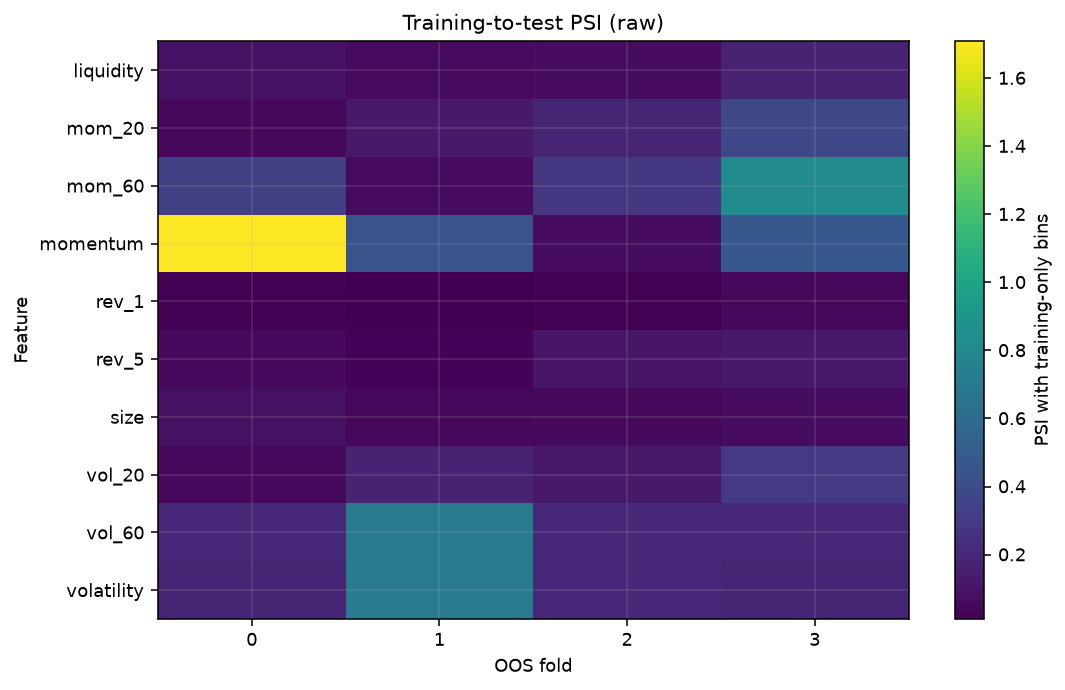

In [5]:
display(Image(filename=str(result / 'figures/feature_drift_psi_raw.png')))

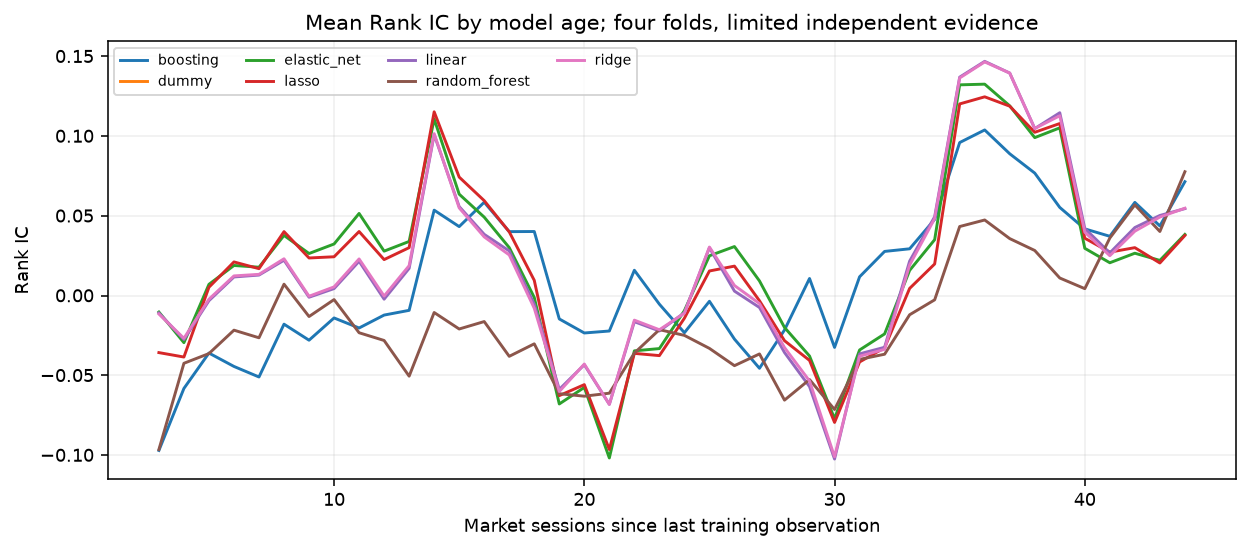

In [6]:
display(Image(filename=str(result / 'figures/model_decay_curve.png')))